# AutoGluon Hands-on Tutorial

**Tutorial goal:** Train and evaluate AutoGluon models that predict NYC Airbnb nightly listing prices, then compare AutoGluon with a Linear Regression baseline.

Results may differ slightly across runs and machine configurations.

## Learning objectives
- Load and clean real-world tabular data; avoid train/test leakage.
- Fit an AutoGluon regression predictor and evaluate MAE, RMSE and R².
- Inspect a leaderboard and permutation feature importance.
- Compare an automated approach to a transparent baseline on identical input features.
- Explore pricing by borough, room type and title-advertised features.

**Setup:** Download `AB_NYC_2019.csv` from [NYC Airbnb Open Data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data). Create a `data` folder in the project directory and place the csv inside it at `data/AB_NYC_2019.csv`. Install the project dependencies before running.

## Lesson 1: Load and understand the data
The target is `price` (USD per night). `room_type`, `neighbourhood`, coordinates, review history and availability can help predict price. Title text (`name`) is an optional advanced feature. 

**Checkpoint:** Which columns could contain identifiers rather than generalizable housing information?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from autogluon.tabular import TabularPredictor
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

DATA_PATH = Path("data/AB_NYC_2019.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Download the dataset and save it at {DATA_PATH}")
raw = pd.read_csv(DATA_PATH)
print("Original shape:", raw.shape)
display(raw.head(3))
display(raw.isna().sum().sort_values(ascending=False).head(10))

Original shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365


last_review            10052
reviews_per_month      10052
host_name                 21
name                      16
neighbourhood_group        0
neighbourhood              0
id                         0
host_id                    0
longitude                  0
latitude                   0
dtype: int64

## Lesson 2: Clean, split, and explain design decisions
We reproduce the portfolio's filtering choices: keep listings available at least 52 days (half the weekends in a year), priced between $15–$1,000, and with known `reviews_per_month`. This means our estimates represent this selected subset, not all NYC listings. Fill missing titles with `No Name` and remove identifiers and unneeded host/date columns.

For AutoGluon, we pass numeric values in their original units, because its tree models generally don't need numeric scaling. The Linear Regression baseline requires categorical encoding. We also scale numerical features as a preprocessing choice.

In [2]:
df = raw.copy()
df["name"] = df["name"].fillna("No Name")
df = df.drop(columns=["last_review", "host_name", "id", "host_id"], errors="ignore")
df = df.dropna(subset=["reviews_per_month"])
df = df.loc[(df["availability_365"] >= 52) & df["price"].between(15, 1000)].copy()

train_data = df.sample(frac=0.8, random_state=42)
test_data = df.drop(train_data.index)
assert set(train_data.index).isdisjoint(set(test_data.index))
print("Clean data:", df.shape, "Train:", train_data.shape, "Test:", test_data.shape)

Clean data: (19630, 12) Train: (15704, 12) Test: (3926, 12)


## Lesson 3: Train an AutoGluon model
For the sake of the walkthrough, the limit was set to five minutes (`TRAINING_TIME_LIMIT=300`). For a longer experiment, increase it or set it to `None`.

**Checkpoint:** Why do we still use a held-out test set when AutoGluon handles internal validation?

In [3]:
TRAINING_TIME_LIMIT = 300  # seconds; set None for unrestricted training
predictor = TabularPredictor(
    label="price", problem_type="regression",
    eval_metric="mean_absolute_error",
    path="AutogluonModels/tutorial_original"
).fit(train_data=train_data, time_limit=TRAINING_TIME_LIMIT)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.11.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          8
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       0.83 GB / 7.92 GB (10.5%)
Disk Space Avail:   4.80 GB / 236.34 GB (2.0%)
	We recommend a minimum available disk space of 10 GB, and large datasets may require more.
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='extreme'  : Use this if you have a GPU. The go-to preset for best results, and the one to use for benchmark comparisons. New in v1.6: far better than 'best' on datasets <100000 samples by using Tabular Foundation Model

## Lesson 4 — Predict and compare models
The leaderboard ranks the tested models.

In [4]:
y_test = test_data["price"]
pred = predictor.predict(test_data)
print("AutoGluon test evaluation:", predictor.evaluate(test_data))
display(predictor.leaderboard(test_data, silent=True).head(12))

AutoGluon test evaluation: {'mean_absolute_error': -42.673683166503906, 'root_mean_squared_error': np.float64(-84.05060721014353), 'mean_squared_error': -7064.50439453125, 'r2': 0.5480332374572754, 'pearsonr': 0.7479983655235538, 'median_absolute_error': -21.445646286010742}


,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,-42.673683,-46.159340,mean_absolute_error,0.906024,0.474283,284.460240,0.018085,0.003087,0.183597,2,True,5
1,CatBoost,-42.874660,-46.814289,mean_absolute_error,0.157487,0.108672,224.010653,0.157487,0.108672,224.010653,1,True,4
2,LightGBM,-46.025074,-48.358208,mean_absolute_error,0.110504,0.032529,1.610268,0.110504,0.032529,1.610268,1,True,2
3,LightGBMXT,-46.121979,-49.083569,mean_absolute_error,0.158334,0.035970,2.577942,0.158334,0.035970,2.577942,1,True,1
4,RandomForestMSE,-46.285755,-49.637989,mean_absolute_error,0.619949,0.329996,58.655722,0.619949,0.329996,58.655722,1,True,3


For additional metrics, calculate MAE/RMSE/R² explicitly.

In [5]:
def metric_row(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

original_metrics = metric_row(y_test, pred)

pd.DataFrame([original_metrics])

,MAE,RMSE,R2
0,42.673683,84.050606,0.548033


**Checkpoint:** What does an MAE of $45 mean across the test listings?

## Lesson 5: Explain feature importance
A large positive importance indicates that shuffling that feature worsened the model's MAE by a larger amount. Importance is **not** proof of causality.

,importance,stddev,p_value,n,p99_high,p99_low
room_type,28.179443,0.238822,1.197063e-05,3,29.547920,26.810967
name,10.455950,0.578726,5.098042e-04,3,13.772116,7.139785
minimum_nights,6.719402,0.224777,1.864013e-04,3,8.007401,5.431404
neighbourhood,4.750534,0.271264,5.425527e-04,3,6.304909,3.196159
longitude,4.226081,0.004902,2.242187e-07,3,4.254168,4.197993
latitude,2.221756,0.156048,8.201640e-04,3,3.115926,1.327586
availability_365,1.583041,0.217161,3.107168e-03,3,2.827397,0.338685
number_of_reviews,1.556344,0.109498,8.229629e-04,3,2.183783,0.928906
calculated_host_listings_count,1.481032,0.057543,2.514067e-04,3,1.810760,1.151304
reviews_per_month,1.196543,0.112776,1.474023e-03,3,1.842764,0.550322


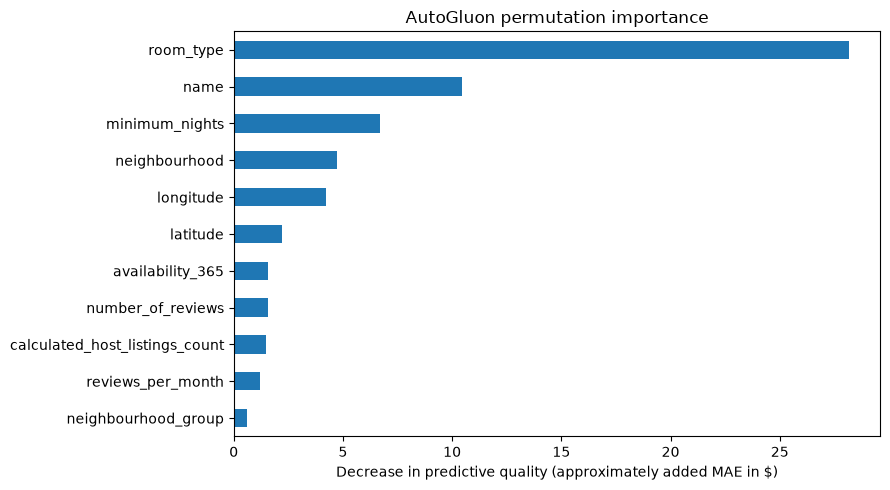

In [6]:
importance = predictor.feature_importance(test_data, num_shuffle_sets=3, silent=True)
display(importance.head(12))
importance["importance"].head(12).sort_values().plot.barh(figsize=(9, 5), title="AutoGluon permutation importance")
plt.xlabel("Decrease in predictive quality (approximately added MAE in $)")
plt.tight_layout()
plt.show()

## Lesson 6: Controlled AutoGluon vs. Linear Regression
The first model includes the `name` which offers a lot of context towards the prediction. For a more meaningful comparison, train a second AutoGluon model without `name`, using the same feature columns and test observations as Linear Regression, for a more direct comparison. AutoGluon and scikit-learn will still use their own preprocessing methods but we will get a more fair comparison.

In [7]:
controlled_train = train_data.drop(columns="name")
controlled_test = test_data.drop(columns="name")
controlled_predictor = TabularPredictor(
    label="price", problem_type="regression", eval_metric="mean_absolute_error",
    path="AutogluonModels/tutorial_controlled"
).fit(train_data=controlled_train, presets="medium", time_limit=TRAINING_TIME_LIMIT)
controlled_pred = controlled_predictor.predict(controlled_test.drop(columns="price"))

Preset alias specified: 'medium' maps to 'medium_quality'.
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.11.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          8
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       1.10 GB / 7.92 GB (13.9%)
Disk Space Avail:   4.80 GB / 236.34 GB (2.0%)
	We recommend a minimum available disk space of 10 GB, and large datasets may require more.
Presets specified: ['medium']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 300s
AutoGluon will save models to "c:\Users\bekel\autogluon_tutorial_v2\AutogluonModels\tutorial_controlled"
Train Data Rows:    15704
Train Data Columns: 10
Label Column:       price
Problem Type:       regression
Preprocessing data...
Using Feature Generators to preprocess the data ...
Fitting AutoMLPi

### A baseline with preprocessing
Unlike AutoGluon, `LinearRegression` needs categorical variables converted to numbers. `ColumnTransformer` scales numerical columns and one-hot encodes categories. These transformations are fitted **only** on the training split.

In [8]:
X_train = controlled_train.drop(columns="price")
X_test = controlled_test.drop(columns="price")
y_train = controlled_train["price"]
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
prep = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scale", MinMaxScaler())]), num_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])
baseline = Pipeline([("preprocessor", prep), ("model", LinearRegression())])
baseline.fit(X_train, y_train)
lr_pred = baseline.predict(X_test)
model_metrics = pd.DataFrame({
    "AutoGluon (with title)": original_metrics,
    "AutoGluon (controlled)": metric_row(y_test, controlled_pred),
    "Linear Regression": metric_row(y_test, lr_pred),
}).T
display(model_metrics.round(2))
print("Controlled AutoGluon MAE improvement vs Linear Regression:",
      f"{100 * (model_metrics.loc['Linear Regression', 'MAE'] - model_metrics.loc['AutoGluon (controlled)', 'MAE']) / model_metrics.loc['Linear Regression', 'MAE']:.1f}%")

,MAE,RMSE,R2
AutoGluon (with title),42.67,84.05,0.55
AutoGluon (controlled),46.40,89.34,0.49
Linear Regression,57.60,99.74,0.36


Controlled AutoGluon MAE improvement vs Linear Regression: 19.5%


**Checkpoint:** 
1. Which approach has the lowest MAE? Does that change after removing title text?
2. How do RMSE and MAE differ?
3. Why is comparing the *original* AutoGluon against Linear Regression less controlled?

## Lesson 7: Pricing trends (bonus)
These charts compare mean and median nightly prices by borough and room type. Expensive listings can pull the mean upward, while the median is less affected by extreme prices. These summaries describe the filtered dataset, not model feature importance or causal relationships.

**Checkpoint:** Where is the gap between mean and median largest, and what might that suggest about listing prices in that group?

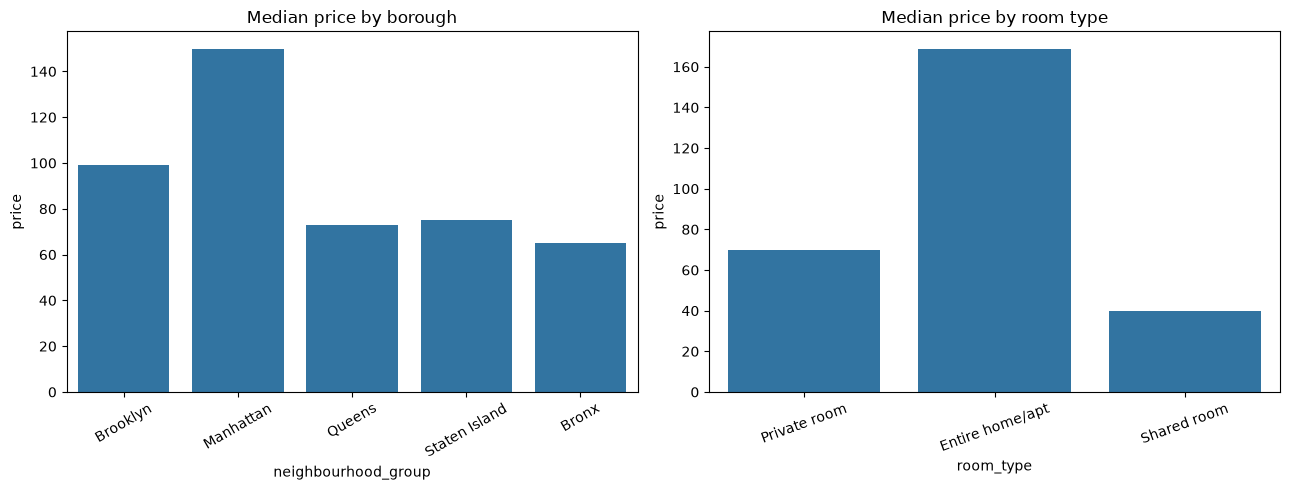

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=df, x="neighbourhood_group", y="price", estimator=np.median, errorbar=None, ax=axes[0])
sns.barplot(data=df, x="room_type", y="price", estimator=np.median, errorbar=None, ax=axes[1])
axes[0].set_title("Median price by borough")
axes[1].set_title("Median price by room type")
axes[0].tick_params(axis="x", rotation=30)
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

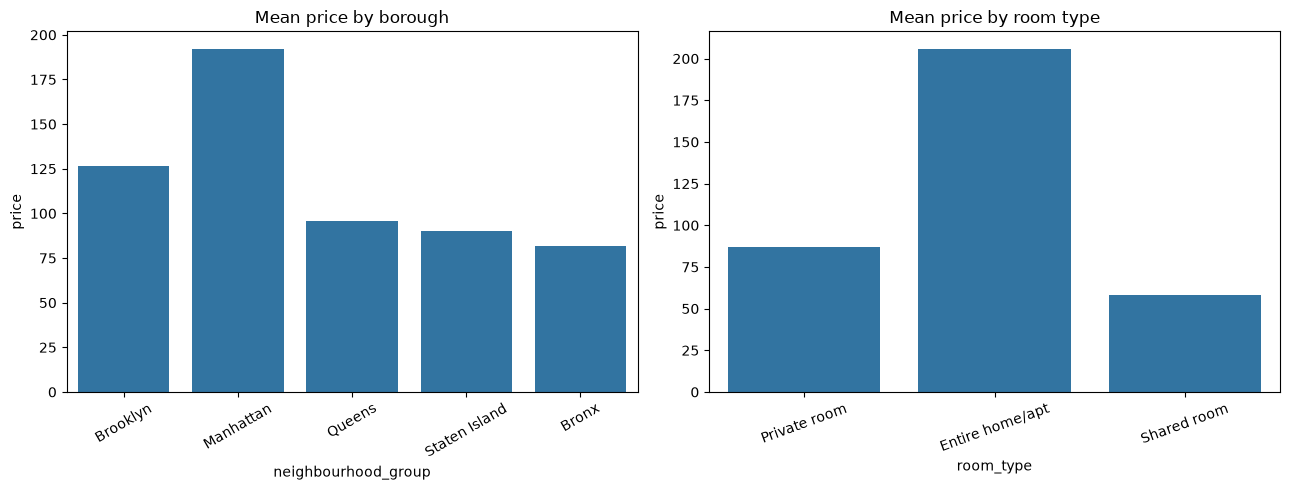

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=df, x="neighbourhood_group", y="price", estimator=np.mean, errorbar=None, ax=axes[0])
sns.barplot(data=df, x="room_type", y="price", estimator=np.mean, errorbar=None, ax=axes[1])
axes[0].set_title("Mean price by borough")
axes[1].set_title("Mean price by room type")
axes[0].tick_params(axis="x", rotation=30)
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## Lesson 8: Title-advertised features (bonus)
Unfortunately the dataset has no amenities field but we can explore the names for keywords to identify the airbnb amenities. 

- **Not guaranteed amenities**
- **Low counts should be interpreted cautiously**


In [11]:
amenities = {"Pool": r"pool", "Rooftop": r"rooftop", "Garden": r"garden",
             "Parking": r"parking|garage", "Laundry": r"washer|dryer|laundry"}
rows = []
for feature, pat in amenities.items():
    mentioned = df["name"].str.contains(rf"\b(?:{pat})\b", case=False, regex=True, na=False)
    rows.append({"Feature": feature, "Count": int(mentioned.sum()),
                 "Median with mention": df.loc[mentioned, "price"].median(),
                 "Median without mention": df.loc[~mentioned, "price"].median()})
amenity_table = pd.DataFrame(rows)
amenity_table["Difference"] = amenity_table["Median with mention"] - amenity_table["Median without mention"]
display(amenity_table.sort_values("Difference", ascending=False))

,Feature,Count,Median with mention,Median without mention,Difference
0,Pool,37,225.0,109.0,116.0
1,Rooftop,149,205.0,108.0,97.0
4,Laundry,131,200.0,109.0,91.0
2,Garden,518,140.0,105.0,35.0
3,Parking,116,107.0,109.0,-2.0


## Lesson 9: Try it yourself

Use the Airbnb dataset to investigate how changing the input features affects price prediction.
1. Choose your features by removing one feature or a related group of features, like latitude and longitude. Explain why you think this change might affect performance.
2. Train a new predictor with `price` as the target, using the tutorial’s training rows, evaluation metric (`mean_absolute_error`), training time limit, and preset. Save your predictor to a new path (`AutogluonModels/lesson9`).
3. Use `.leaderboard()` without test data to identify the three models with the best validation scores.
4. Generate predictions on the same test rows, using your selected feature columns. Calculate test MAE and compare it with the original predictor’s test MAE.
5. Calculate feature importance and explain what the three highest-ranked features suggest. Consider whether correlated features could affect these results.
Reflection: In a short paragraph, explain your feature changes and whether test MAE improved or got worse.

**Keep the test data separate from training, and choose your features before checking the test results**

## Lesson 10: Review
**What you learned:** Defining a tabular regression task, training and evaluating AutoGluon predictors, comparing results with a baseline, and interpreting feature importance.

**Limitations:** 
- The listings are from 2019
- Missing-review rows were removed
- Only listings priced between $15 and $1000 per night were included
- Title mentions are imperfect amenity proxies
